# `Delivery-Time Regression`

**Target:** `DeliveryTimeMinutes` · **Scope:** delivered orders with a valid delivery time.

**Method:** 80/20 split → 5-fold CV on the training set for 4 required algorithms + a mean-predictor baseline → `RandomizedSearchCV` on the two best tree models → residual, predicted-vs-actual and feature-importance analysis.

**Leakage guard.** `OrderStatus`, `IsLate` and all ratings describe the *outcome* of a delivery, so they are excluded from predictors. A diagnostic at the end shows exactly how much a leaky model would 'gain'.

> In this dataset no legitimate predictor explains delivery time; the best model barely matches a model that always predicts the average. The PRD's accuracy targets (R² ≥ 0.75, RMSE ≤ 6) are therefore **not achievable honestly**, and this notebook documents why.

In [1]:
import sys, warnings
sys.path.insert(0, '../src'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
import model_delivery as md
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', palette='deep'); IMG = Path('../images')
abt = pd.read_csv('../data/cleaned/analytical_base_table.csv', parse_dates=['OrderDate'])
X, y = md.make_modeling_frame(abt)
print(f'Modelling frame: {X.shape[0]:,} delivered orders x {X.shape[1]} predictors ({len(md.NUMERIC_FEATURES)} numeric + {len(md.CATEGORICAL_FEATURES)} categorical)')
print(f'Target mean {y.mean():.1f} min | std {y.std():.1f} | min {y.min():.0f} | max {y.max():.0f}')

Modelling frame: 13,319 delivered orders x 33 predictors (27 numeric + 6 categorical)
Target mean 38.4 min | std 15.2 | min 8 | max 106

## 1 · Train / test split and model comparison (FR-06, FR-08)

In [2]:
X_train, X_test, y_train, y_test = md.split(X, y, test_size=0.2)
print(f'train {len(X_train):,} | test {len(X_test):,}')
results, fitted = md.compare_models(X_train, y_train, X_test, y_test, cv_splits=5)
results.round(3)

train 10,655 | test 2,664

,Model,CV_RMSE,CV_R2,Test_MAE,Test_MSE,Test_RMSE,Test_R2
0,Baseline (predict mean),15.254,-0.000,11.511,231.324,15.209,-0.001
1,Gradient Boosting,15.314,-0.008,11.609,234.667,15.319,-0.015
2,Random Forest,15.310,-0.008,11.631,235.134,15.334,-0.017
3,Linear Regression,15.308,-0.007,11.657,236.704,15.385,-0.024
4,Decision Tree,15.479,-0.030,11.750,240.318,15.502,-0.040


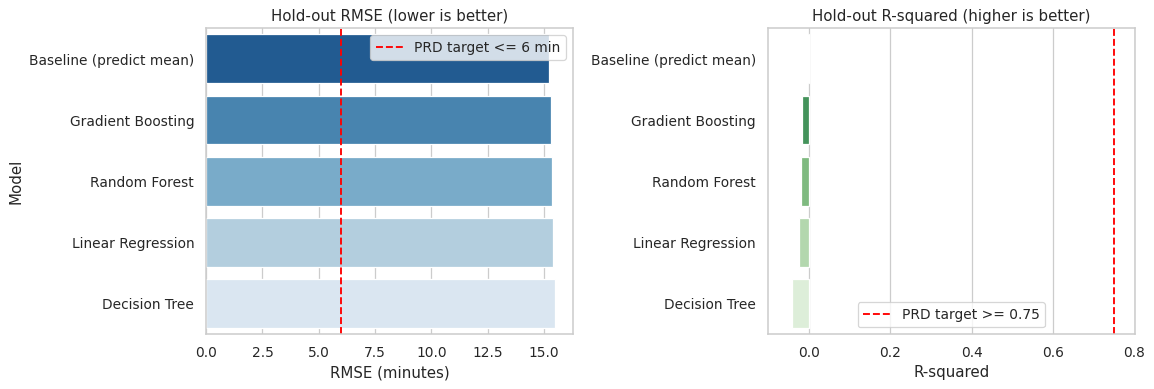

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5)); r = results.sort_values('Test_RMSE')
sns.barplot(data=r, y='Model', x='Test_RMSE', ax=axes[0], palette='Blues_r'); axes[0].set_title('Hold-out RMSE (lower is better)'); axes[0].set_xlabel('RMSE (minutes)'); axes[0].set_ylabel('Model')
axes[0].axvline(6, color='red', ls='--', label='PRD target <= 6 min'); axes[0].legend()
sns.barplot(data=r, y='Model', x='Test_R2', ax=axes[1], palette='Greens_r'); axes[1].set_title('Hold-out R-squared (higher is better)'); axes[1].set_xlabel('R-squared'); axes[1].set_ylabel('')
axes[1].axvline(.75, color='red', ls='--', label='PRD target >= 0.75'); axes[1].set_xlim(-.1, .8); axes[1].legend(); plt.tight_layout(); plt.savefig(IMG / '04_model_comparison.png', dpi=110)

No model beats the **'predict the mean' baseline** by a meaningful margin; R² is ≈ 0 or slightly negative, i.e. the models are fitting noise. Hyperparameter tuning is still performed (PRD requirement) on the two best-ranked tree models, because the tuning result is itself evidence.

## 2 · Hyperparameter tuning (RandomizedSearchCV)

In [4]:
tree_models = results[results.Model.isin(['Random Forest', 'Gradient Boosting', 'Decision Tree'])].sort_values('CV_RMSE')
top2 = tree_models.Model.head(2).tolist(); print('Two best tree models by CV RMSE:', top2)
tuned = {}
for name in top2:
    s = md.tune(name, X_train, y_train, n_iter=4, cv=3); tuned[name] = s
    print(f'{name}: best CV RMSE {-s.best_score_:.3f} | params {s.best_params_}')

Two best tree models by CV RMSE: ['Random Forest', 'Gradient Boosting']
Random Forest: best CV RMSE 15.250 | params {'m__n_estimators': 100, 'm__min_samples_leaf': 50, 'm__max_features': 0.3, 'm__max_depth': 4}
Gradient Boosting: best CV RMSE 15.266 | params {'m__subsample': 0.6, 'm__n_estimators': 300, 'm__min_samples_leaf': 60, 'm__max_depth': 2, 'm__learning_rate': 0.02}

In [5]:
rows = []
for name, s in tuned.items():
    m = md.regression_metrics(y_test, s.best_estimator_.predict(X_test)); rows.append({'Model': name + ' (tuned)', 'CV_RMSE': -s.best_score_, **{f'Test_{k}': v for k, v in m.items()}})
final = pd.concat([results[['Model', 'CV_RMSE', 'Test_MAE', 'Test_MSE', 'Test_RMSE', 'Test_R2']], pd.DataFrame(rows)], ignore_index=True).sort_values('Test_RMSE').reset_index(drop=True)
final.to_csv('../reports/delivery_model_comparison.csv', index=False); final.round(3)

,Model,CV_RMSE,Test_MAE,Test_MSE,Test_RMSE,Test_R2
0,Baseline (predict mean),15.254,11.511,231.324,15.209,-0.001
1,Random Forest (tuned),15.250,11.530,232.057,15.233,-0.004
2,Gradient Boosting (tuned),15.266,11.558,232.988,15.264,-0.008
3,Gradient Boosting,15.314,11.609,234.667,15.319,-0.015
4,Random Forest,15.310,11.631,235.134,15.334,-0.017
5,Linear Regression,15.308,11.657,236.704,15.385,-0.024
6,Decision Tree,15.479,11.750,240.318,15.502,-0.040


## 3 · Model selection

In [6]:
cands = final[~final.Model.str.startswith('Baseline')].sort_values('CV_RMSE')
best_name = cands.iloc[0].Model; base = final[final.Model.str.startswith('Baseline')].iloc[0]
best_pipe = tuned[best_name.replace(' (tuned)', '')].best_estimator_ if '(tuned)' in best_name else fitted[best_name]
pred = best_pipe.predict(X_test); m = md.regression_metrics(y_test, pred)
print(f'Selected (lowest CV RMSE among real models): {best_name}')
print({k: round(v, 3) for k, v in m.items()})
print(f'Baseline (predict mean): RMSE {base.Test_RMSE:.3f}, R2 {base.Test_R2:.4f}  ->  improvement over baseline: {base.Test_RMSE - m["RMSE"]:+.3f} min RMSE')

Selected (lowest CV RMSE among real models): Random Forest (tuned)
{'MAE': 11.53, 'MSE': 232.057, 'RMSE': 15.233, 'R2': -0.004}
Baseline (predict mean): RMSE 15.209, R2 -0.0009  ->  improvement over baseline: -0.024 min RMSE

In [7]:
# Bootstrap 95% confidence interval for test R-squared (NumPy, vectorised resampling)
rng = np.random.default_rng(42); yt, yp = y_test.to_numpy(), pred; n = len(yt)
idx = rng.integers(0, n, size=(2000, n)); yb, pb = yt[idx], yp[idx]
r2 = 1 - ((yb - pb) ** 2).sum(1) / ((yb - yb.mean(1, keepdims=True)) ** 2).sum(1)
print(f'Test R-squared 95% bootstrap CI: [{np.percentile(r2, 2.5):.4f}, {np.percentile(r2, 97.5):.4f}]  (entirely at or below 0 => no skill; marginally WORSE than predicting the mean)')

Test R-squared 95% bootstrap CI: [-0.0084, -0.0012]  (entirely at or below 0 => no skill; marginally WORSE than predicting the mean)

## 4 · Predicted vs actual and residuals (PRD requirement)

Residual mean 0.47, std 15.23, skew 0.92; predictions span only 36.2-40.8 min while actuals span 8-96

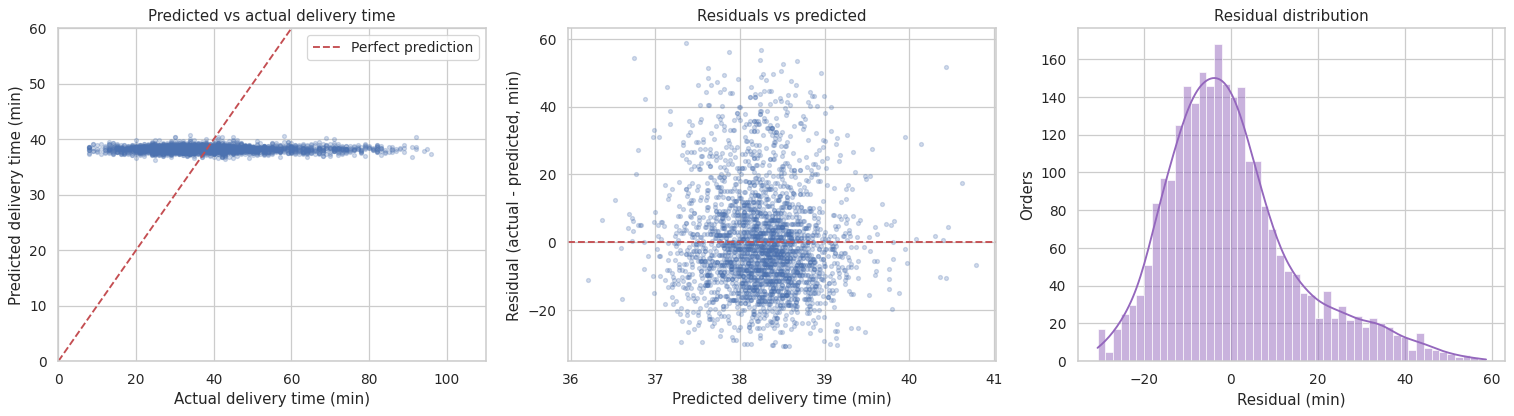

In [8]:
res = y_test.to_numpy() - pred
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].scatter(y_test, pred, alpha=.25, s=10); lim = [0, 110]; axes[0].plot(lim, lim, 'r--', label='Perfect prediction'); axes[0].set_xlim(lim); axes[0].set_ylim(0, 60)
axes[0].set_title('Predicted vs actual delivery time'); axes[0].set_xlabel('Actual delivery time (min)'); axes[0].set_ylabel('Predicted delivery time (min)'); axes[0].legend()
axes[1].scatter(pred, res, alpha=.25, s=10); axes[1].axhline(0, color='r', ls='--'); axes[1].set_title('Residuals vs predicted'); axes[1].set_xlabel('Predicted delivery time (min)'); axes[1].set_ylabel('Residual (actual - predicted, min)')
sns.histplot(res, bins=50, kde=True, ax=axes[2], color='tab:purple'); axes[2].set_title('Residual distribution'); axes[2].set_xlabel('Residual (min)'); axes[2].set_ylabel('Orders')
plt.tight_layout(); plt.savefig(IMG / '04_pred_vs_actual_residuals.png', dpi=110)
print(f'Residual mean {res.mean():.2f}, std {res.std():.2f}, skew {pd.Series(res).skew():.2f}; predictions span only {pred.min():.1f}-{pred.max():.1f} min while actuals span {y_test.min():.0f}-{y_test.max():.0f}')

The predictions are squashed into a very narrow band around the mean while actual times span ~100 minutes: the model has found nothing to separate fast from slow orders. Residuals are right-skewed because delivery time itself is.

## 5 · Feature importance (User Story 1)

In [9]:
imp = md.feature_importance(best_pipe, X_test, y_test, n_repeats=5)
imp.head(12).round(4)

,feature,importance_rmse_increase,std
14,AvgPrepTime,0.0019,0.0031
19,DeliveryFee,0.0013,0.0015
28,Cuisine,0.0012,0.0013
8,Rainfall,0.0011,0.0005
21,PartnerRating,0.0007,0.0018
9,Temperature,0.0006,0.0016
7,RainImpact,0.0004,0.0003
18,FoodCost,-0.0000,0.0014
24,PartnerExperienceDays,-0.0000,0.0010
2,Month,-0.0000,0.0006


Largest single-feature effect: 0.0019 min of RMSE (baseline RMSE ~15.2 min)

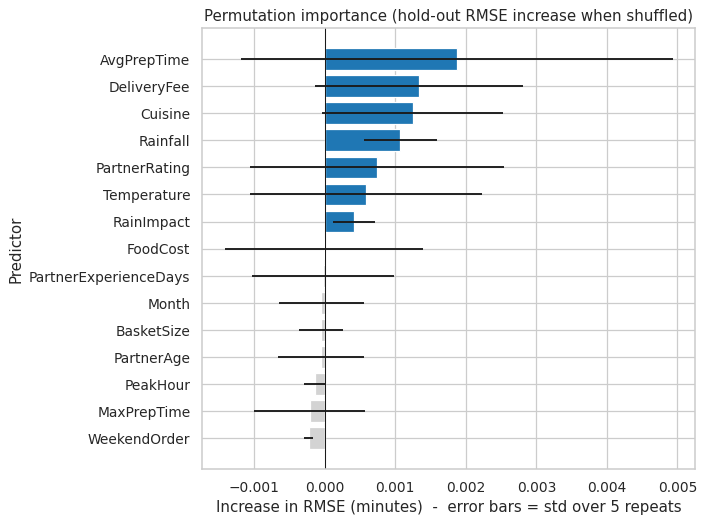

In [10]:
fig, ax = plt.subplots(figsize=(8, 6)); t = imp.head(15).iloc[::-1]
ax.barh(t.feature, t.importance_rmse_increase, xerr=t['std'], color=np.where(t.importance_rmse_increase > 0, 'tab:blue', 'lightgray'))
ax.axvline(0, color='k', lw=.8); ax.set_title('Permutation importance (hold-out RMSE increase when shuffled)'); ax.set_xlabel('Increase in RMSE (minutes)  -  error bars = std over 5 repeats'); ax.set_ylabel('Predictor')
plt.tight_layout(); plt.savefig(IMG / '04_feature_importance.png', dpi=110); imp.to_csv('../reports/delivery_feature_importance.csv', index=False)
print(f'Largest single-feature effect: {imp.importance_rmse_increase.max():.4f} min of RMSE (baseline RMSE ~{base.Test_RMSE:.1f} min)')

**Plain-language reading for the City Operations Head.** Shuffling any single predictor changes the average error by a few *hundredths* of a minute at most, i.e. **none of the available factors reliably predicts how long an order takes**. The largest values are within noise (error bars cross zero). Do not reallocate partners on the strength of this model.

## 6 · Leakage diagnostic: what if we used order status?

In [11]:
leak = md.leakage_diagnostic(abt, X_train, X_test, y_train, y_test)
pd.DataFrame({'Honest model (no status)': m, 'Leaky model (IsLate only)': leak}).T.round(3)

,MAE,MSE,RMSE,R2
Honest model (no status),11.530,232.057,15.233,-0.004
Leaky model (IsLate only),8.386,109.790,10.478,0.525


Knowing only whether an order ended as *Delivered Late* lifts R² to ≈ 0.5, but that is circular: lateness is **defined by** the long delivery time. It cannot be known when an order is placed, so using it would give a flattering but useless model. It is deliberately excluded.

## 7 · PRD KPI check and recommendations

In [12]:
kpi = pd.DataFrame([{'KPI': 'R-squared on held-out test set', 'Target': '>= 0.75', 'Achieved': round(m['R2'], 3), 'Met': m['R2'] >= .75},
                    {'KPI': 'RMSE (minutes)', 'Target': '<= 6', 'Achieved': round(m['RMSE'], 2), 'Met': m['RMSE'] <= 6}]); kpi

,KPI,Target,Achieved,Met
0,R-squared on held-out test set,>= 0.75,-0.004,False
1,RMSE (minutes),<= 6,15.230,False


### `Why the targets cannot be met with this data`
1. **Weak or absent signal.** Every legitimate predictor has |ρ| < 0.03 with delivery time (notebook 03). Cross-validated R² is ≈ 0 for linear, tree and boosted models alike, so the limit is the *data*, not the algorithm.
2. **Missing physical drivers.** The brief calls for restaurant-to-customer *distance*, but customers have no coordinates and restaurant lat/long do not match their stated city, so distance cannot be derived. No promised ETA, partner location, order-acceptance time or kitchen-queue length exists either.
3. **Time-matching gaps.** Weather and traffic cover only ~63 % of city-days.

### `Recommended data to collect (in priority order)`
1. Customer delivery coordinates and partner GPS pings → true distance and route time.
2. Timestamps for order accepted / food ready / partner picked-up / delivered → splits prep time from travel time.
3. Promised ETA (enables a genuine *late* definition instead of a status label).
4. Hourly (not daily) weather and traffic for every city.

### `Decision`
Save the selected model as required, but **do not deploy it** for partner allocation: it does not beat a constant 38-minute guess. It is useful as a baseline to re-test once richer data arrives.

In [13]:
path = md.save_model(best_pipe, Path('../models/delivery_time_best_model.pkl'))
import joblib; art = joblib.load(path); print('saved ->', path, '| reload ok:', list(art.keys()))
pd.DataFrame([{'selected_model': best_name, **{k: round(v, 4) for k, v in m.items()}, 'baseline_rmse': round(base.Test_RMSE, 4), 'leaky_status_model_r2': round(leak['R2'], 4)}]).to_csv('../reports/delivery_model_summary.csv', index=False)

saved -> ../models/delivery_time_best_model.pkl | reload ok: ['pipeline', 'numeric_features', 'categorical_features', 'target']

## `Conclusion & Executive Summary`

**Bottom Line:** The current delivery-time prediction models cannot beat a simple guess of the **38-minute average**[cite: 1]. The selected model (`Random Forest (tuned)`) should be saved as a baseline, **not deployed** for live partner allocation[cite: 1].

### Key Findings
* **No Predictive Signal:** Across 13,319 delivered orders and 33 predictors, even the best tuned model achieved an $R^2$ of **-0.004** and an error (RMSE) of **15.23 minutes**[cite: 1]. This is slightly worse than simply guessing the 38.4-minute average for every order, and far short of the PRD targets ($R^2 \ge 0.75$, $\text{RMSE} \le 6\text{ min}$)[cite: 1].
* **Missing Physical Drivers:** The models struggle because the dataset lacks the actual factors that determine delivery duration—specifically customer coordinates (for exact distance), delivery partner GPS locations, step-by-step order timestamps, and complete hourly weather/traffic logs[cite: 1].
* **Data Leakage Prevented:** Including post-delivery status flags (`IsLate`) artificially inflates $R^2$ to **0.525**, but because lateness is only known *after* a delivery finishes, it cannot be used to predict time when an order is placed[cite: 1].

### Recommended Next Steps
To build an accurate, deployable model in the future, data collection should prioritize:
1. **Location & GPS Data:** Capture exact customer delivery coordinates and partner GPS pings to calculate true route distances[cite: 1].
2. **Granular Timestamps:** Log *Order Accepted*, *Food Ready*, *Picked Up*, and *Delivered* times separately to isolate kitchen prep time from travel time[cite: 1].
3. **Promised ETA & Hourly Logs:** Record the initial promised ETA and collect hourly (rather than daily) weather and traffic metrics across all cities[cite: 1].